# ML Assignment 5 – KNN on Diabetes Dataset
**Problem Statement:** Implement K-Nearest Neighbors algorithm on diabetes.csv dataset. Compute confusion matrix, accuracy, error rate, precision and recall on the given dataset.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score, classification_report

In [2]:
df = pd.read_csv('diabetes.csv')
print(df.shape)
df.head()

(768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,Pedigree,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [3]:
print(df.isnull().sum())
df.describe().T

Pregnancies      0
Glucose          0
BloodPressure    0
SkinThickness    0
Insulin          0
BMI              0
Pedigree         0
Age              0
Outcome          0
dtype: int64


,count,mean,std,min,25%,50%,75%,max
Pregnancies,768.0,3.845052,3.369578,0.000,1.00000,3.0000,6.00000,17.00
Glucose,768.0,120.894531,31.972618,0.000,99.00000,117.0000,140.25000,199.00
BloodPressure,768.0,69.105469,19.355807,0.000,62.00000,72.0000,80.00000,122.00
SkinThickness,768.0,20.536458,15.952218,0.000,0.00000,23.0000,32.00000,99.00
Insulin,768.0,79.799479,115.244002,0.000,0.00000,30.5000,127.25000,846.00
BMI,768.0,31.992578,7.884160,0.000,27.30000,32.0000,36.60000,67.10
Pedigree,768.0,0.471876,0.331329,0.078,0.24375,0.3725,0.62625,2.42
Age,768.0,33.240885,11.760232,21.000,24.00000,29.0000,41.00000,81.00
Outcome,768.0,0.348958,0.476951,0.000,0.00000,0.0000,1.00000,1.00


In [4]:
# Zero is not a valid value for these medical columns -> replace with column mean
for col in ['Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI']:
    df[col] = df[col].replace(0, np.nan)
    df[col] = df[col].fillna(df[col].mean())
df.head()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,Pedigree,Age,Outcome
0,6,148.0,72.0,35.00000,155.548223,33.6,0.627,50,1
1,1,85.0,66.0,29.00000,155.548223,26.6,0.351,31,0
2,8,183.0,64.0,29.15342,155.548223,23.3,0.672,32,1
3,1,89.0,66.0,23.00000,94.000000,28.1,0.167,21,0
4,0,137.0,40.0,35.00000,168.000000,43.1,2.288,33,1


In [5]:
X = df.drop(columns=['Outcome'])
y = df['Outcome']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()   # KNN is distance based, so scaling is important
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

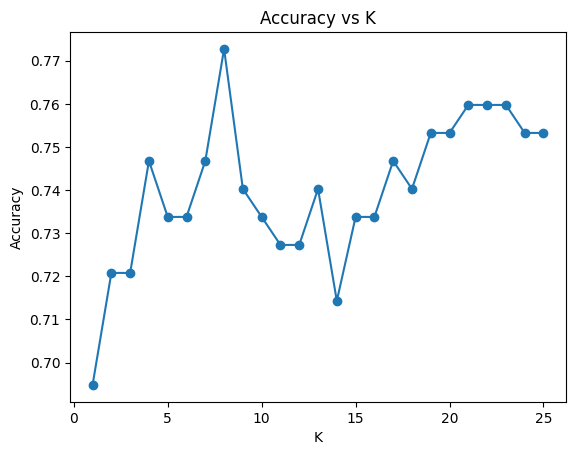

Best K = 8


In [6]:
# Find best K
acc = []
for k in range(1, 26):
    knn = KNeighborsClassifier(n_neighbors=k).fit(X_train, y_train)
    acc.append(accuracy_score(y_test, knn.predict(X_test)))
best_k = int(np.argmax(acc)) + 1
plt.plot(range(1, 26), acc, marker='o')
plt.xlabel('K'); plt.ylabel('Accuracy'); plt.title('Accuracy vs K'); plt.show()
print('Best K =', best_k)

In [7]:
knn = KNeighborsClassifier(n_neighbors=best_k)
knn.fit(X_train, y_train)
y_pred = knn.predict(X_test)

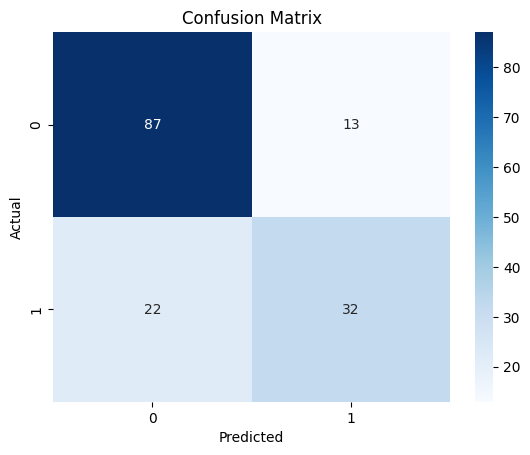

Confusion Matrix:
 [[87 13]
 [22 32]]
TP=32, TN=87, FP=13, FN=22
Accuracy   = (TP+TN)/Total = 0.7727
Error rate = 1 - Accuracy  = 0.2273
Precision  = TP/(TP+FP)    = 0.7111
Recall     = TP/(TP+FN)    = 0.5926
F1 score                   = 0.6465


In [8]:
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.title('Confusion Matrix'); plt.show()

accuracy = accuracy_score(y_test, y_pred)
print('Confusion Matrix:\n', cm)
print(f'TP={tp}, TN={tn}, FP={fp}, FN={fn}')
print('Accuracy   = (TP+TN)/Total =', round(accuracy, 4))
print('Error rate = 1 - Accuracy  =', round(1 - accuracy, 4))
print('Precision  = TP/(TP+FP)    =', round(precision_score(y_test, y_pred), 4))
print('Recall     = TP/(TP+FN)    =', round(recall_score(y_test, y_pred), 4))
print('F1 score                   =', round(f1_score(y_test, y_pred), 4))

In [9]:
print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.80      0.87      0.83       100
           1       0.71      0.59      0.65        54

    accuracy                           0.77       154
   macro avg       0.75      0.73      0.74       154
weighted avg       0.77      0.77      0.77       154
